<a href="https://colab.research.google.com/github/LujainAldujain/Data_Mining_Project/blob/main/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#[1] Problem

#[2] Data Mining Task

#[3] Data

#[4] Data preprocessing

#[5] Data Mining Technique

### 5.1 Classification Technique (Decision Tree - Gini Index)
In this section, we apply the **Decision Tree Classifier** using the **Gini Index** as the attribute selection measure.
- **Tool/Library:** We utilize the `DecisionTreeClassifier` from Python's `scikit-learn` library (`sklearn.tree`).
- **Gini Index Metric:** Measures the impurity of a data partition. The algorithm recursively splits the data to minimize impurity and maximize information purity at each node.

### 5.2 Classification Technique (Decision Tree - Entropy / Information Gain)

In this section, we apply the **Decision Tree Classifier** using **Entropy (Information Gain)** as the attribute selection measure.

* **Why?** Decision trees are easy to interpret. Entropy measures the impurity of a node, and the algorithm splits on the attribute with the highest Information Gain (the largest reduction in entropy). It also lets us compare Entropy with the Gini Index on the same dataset.
* **How?** The preprocessed data is split into three partitions (90/10, 80/20, 70/30). A tree is trained on each using `criterion="entropy"`, then evaluated with accuracy and a confusion matrix, and the tree is visualized.
* **Tools/Library:** `scikit-learn` (`train_test_split`, `DecisionTreeClassifier`, `plot_tree`, `accuracy_score`, `confusion_matrix`), `pandas`, and `matplotlib`.

### 5.1 Classification Technique – Decision Tree

For the classification task, a **Decision Tree Classifier** is used to predict whether a customer will churn (Yes/No), using two attribute selection measures: **Gini Index** and **Entropy (Information Gain)**.

**Why Decision Tree?**

* It is easy to interpret and visualize.
* It handles numerical and categorical features (after preprocessing).
* **Gini Index** measures the impurity of a node, and the algorithm chooses the split that reduces it the most.
* **Entropy (Information Gain)** measures the disorder of a node, and the algorithm chooses the attribute with the highest Information Gain.
* Using both measures on the same data lets us compare them fairly.

**How it is applied (Python packages and methods):**

* `pandas` (`df.drop`, `df[...]`) is used to create:
  * `X`: all input features (the `customerID` and `Churn` columns are removed)
  * `y`: the target column `Churn`
* The dataset is split into training and testing sets using `train_test_split` from `sklearn.model_selection` with three ratios (90/10, 80/20, 70/30) and `random_state=1`.
* The classifier is built using `DecisionTreeClassifier` from `sklearn.tree` with two criteria:
  * `criterion="gini"`
  * `criterion="entropy"`
* The same splits and settings are used for both measures, so the results are directly comparable.
* Model performance is evaluated on the testing set using `accuracy_score` and `confusion_matrix` from `sklearn.metrics`.
* The trees and confusion matrices are visualized using `plot_tree`, `ConfusionMatrixDisplay` and `matplotlib` (the trees are displayed up to depth 3 for readability).

#[6] Evaluation and Comparison

### 6.1 Evaluation and Comparison for Gini Index Classification
To evaluate the performance of the Decision Tree model using the **Gini Index**, we tested three different partition sizes for training and testing:
1. **90% Training / 10% Testing**
2. **80% Training / 20% Testing**
3. **70% Training / 30% Testing**

Below are the accuracy scores, confusion matrices, and visualizations for each partition.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn import tree

url = "https://raw.githubusercontent.com/LujainAldujain/Data_Mining_Project/refs/heads/main/Dataset/Preprocessed_dataset.csv"
df = pd.read_csv(url)

X = df.drop(columns=['Churn'])
drop_cols = ['Churn', 'customerID']
X = df.drop(columns=[c for c in drop_cols if c in df.columns])
cn = df['Churn'].unique().astype(str)
fn = X.columns.tolist()

X_train_90, X_test_90, y_train_90, y_test_90 = train_test_split(X, y, test_size=0.1, random_state=1)
clf_gini_90 = DecisionTreeClassifier(criterion="gini", random_state=42)
clf_gini_90.fit(X_train_90, y_train_90)
y_pred_90 = clf_gini_90.predict(X_test_90)

print("--- 90% Training / 10% Testing (Gini) ---")
print("Accuracy:", metrics.accuracy_score(y_test_90, y_pred_90))
print("Confusion Matrix:\n\n", confusion_matrix(y_test_90, y_pred_90))

X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(X, y, test_size=0.2, random_state=1)
clf_gini_80 = DecisionTreeClassifier(criterion="gini", random_state=42)
clf_gini_80.fit(X_train_80, y_train_80)
y_pred_80 = clf_gini_80.predict(X_test_80)

print("\n--- 80% Training / 20% Testing (Gini) ---")
print("Accuracy:", metrics.accuracy_score(y_test_80, y_pred_80))
print("Confusion Matrix:\n\n", confusion_matrix(y_test_80, y_pred_80))

X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(X, y, test_size=0.3, random_state=1)
clf_gini_70 = DecisionTreeClassifier(criterion="gini", random_state=42)
clf_gini_70.fit(X_train_70, y_train_70)
y_pred_70 = clf_gini_70.predict(X_test_70)

print("\n--- 70% Training / 30% Testing (Gini) ---")
print("Accuracy:", metrics.accuracy_score(y_test_70, y_pred_70))
print("Confusion Matrix:\n\n", confusion_matrix(y_test_70, y_pred_70))

--- 90% Training / 10% Testing (Gini) ---
Accuracy: 0.7262411347517731
Confusion Matrix:

 [[420 113]
 [ 80  92]]

--- 80% Training / 20% Testing (Gini) ---
Accuracy: 0.7274662881476224
Confusion Matrix:

 [[850 211]
 [173 175]]

--- 70% Training / 30% Testing (Gini) ---
Accuracy: 0.7368670137245622
Confusion Matrix:

 [[1287  298]
 [ 258  270]]


#### Gini Index Performance Summary Table
| Partition Size | Accuracy (Gini Index) |
| :--- | :--- |
| **90% Training / 10% Testing** | 0.7262411347517731|
| **80% Training / 20% Testing** | 0.7274662881476224 |
| **70% Training / 30% Testing** | 0.7368670137245622 |

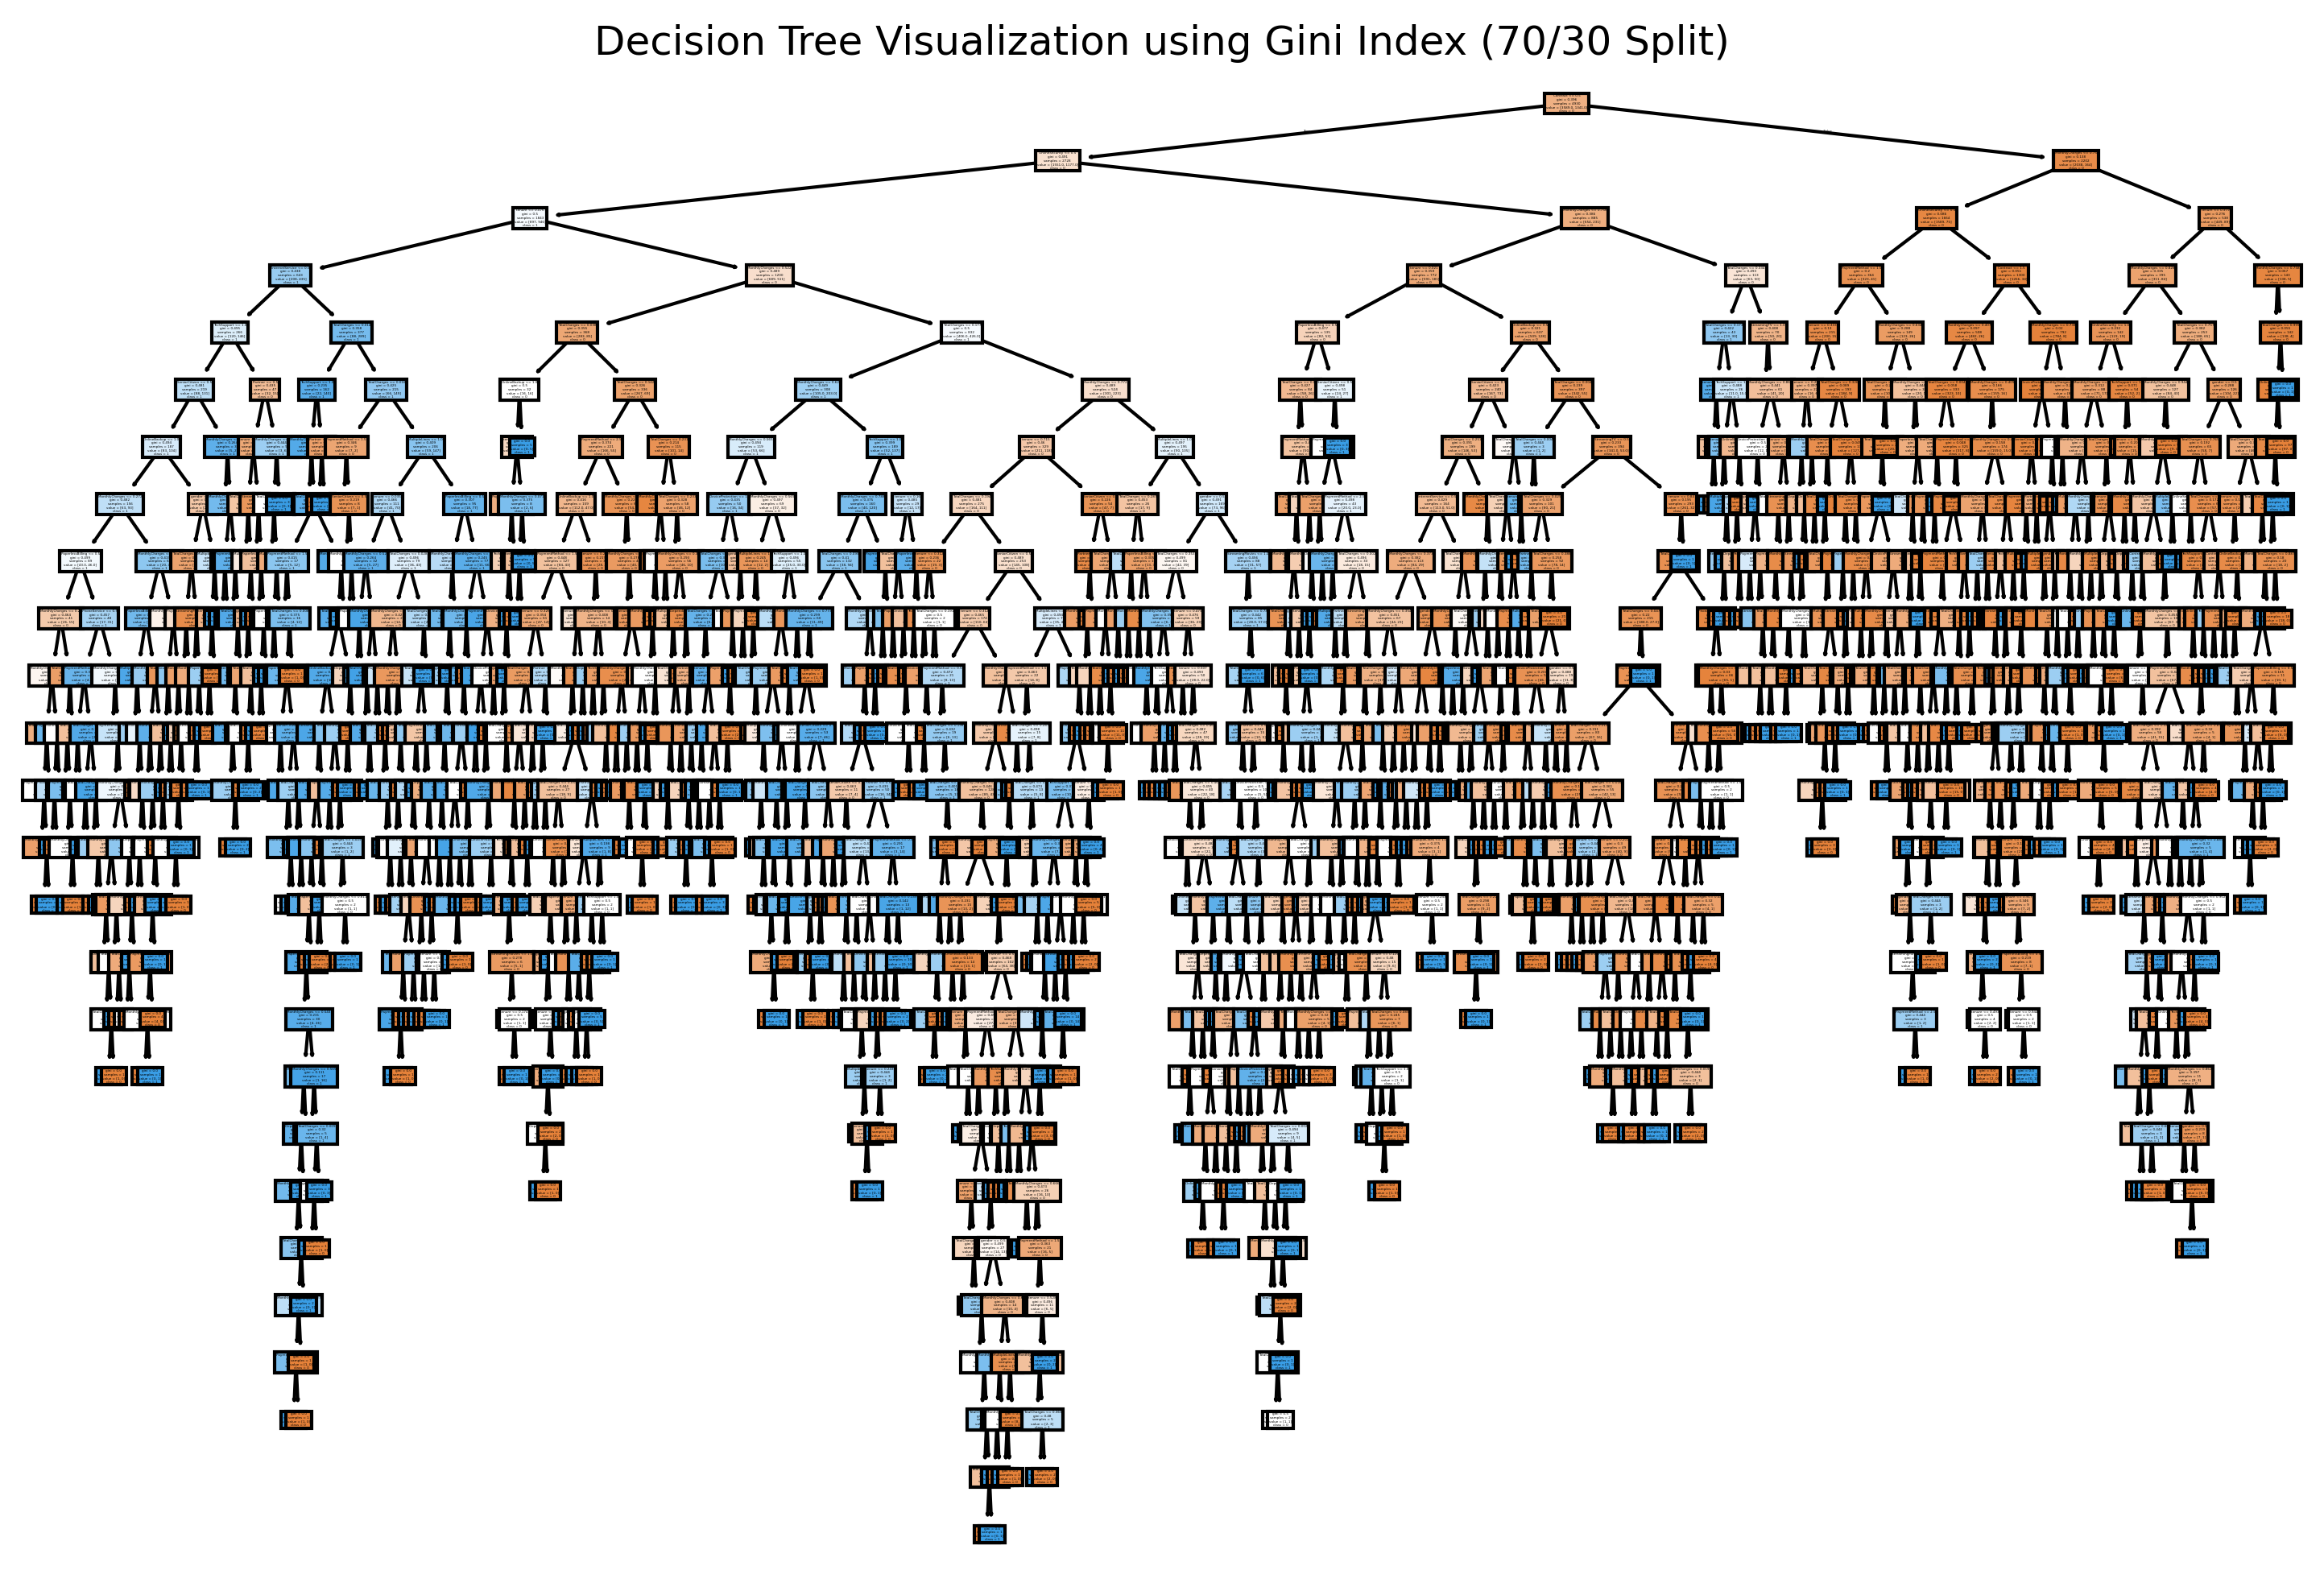

<Figure size 600x600 with 0 Axes>

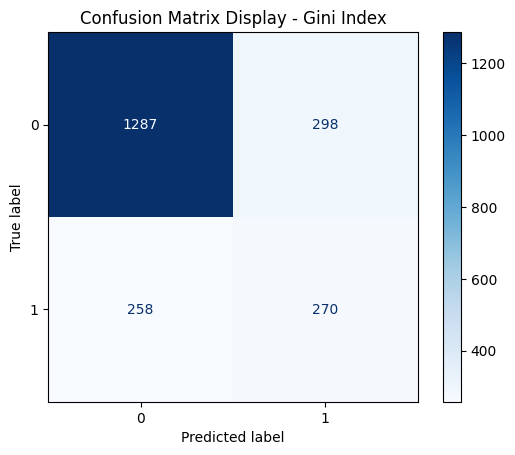

In [ ]:
plt.figure(figsize=(12, 8) , dpi=300)
tree.plot_tree(clf_gini_70, feature_names=fn, class_names=cn, filled=True)
plt.title("Decision Tree Visualization using Gini Index (70/30 Split)")
plt.show()

plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay.from_estimator(clf_gini_70, X_test_70, y_test_70, display_labels=cn, cmap=plt.cm.Blues)
plt.title("Confusion Matrix Display - Gini Index")
plt.show()

### 6.2 Evaluation and Comparison for Entropy (Information Gain) Classification

To evaluate the performance of the Decision Tree model using **Entropy (Information Gain)**, we tested the same three partition sizes for training and testing:

1. **90% Training / 10% Testing**
2. **80% Training / 20% Testing**
3. **70% Training / 30% Testing**

Below are the accuracy scores, confusion matrices, and visualizations for each partition.

--- 90/10 (Entropy) ---
Accuracy: 0.7134751773049646
Confusion Matrix:
 [[412 121]
 [ 81  91]]


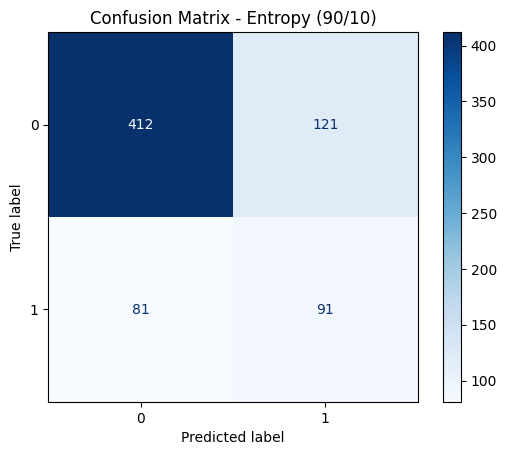

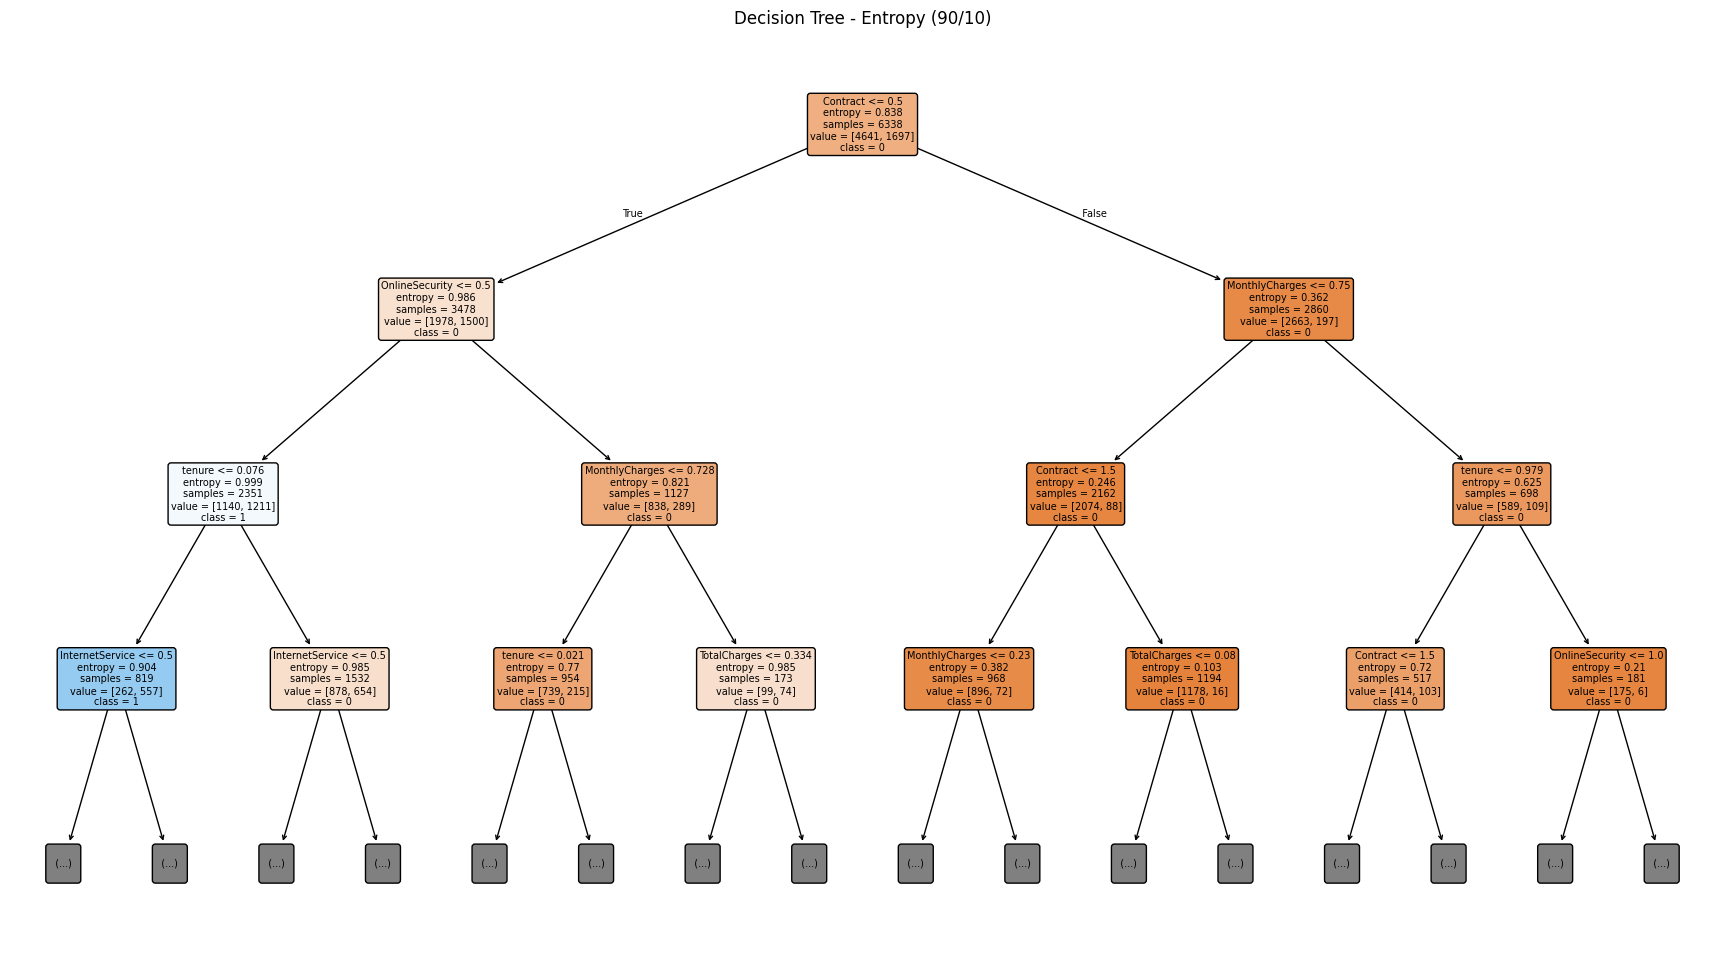

--- 80/20 (Entropy) ---
Accuracy: 0.7359829666430092
Confusion Matrix:
 [[854 207]
 [165 183]]


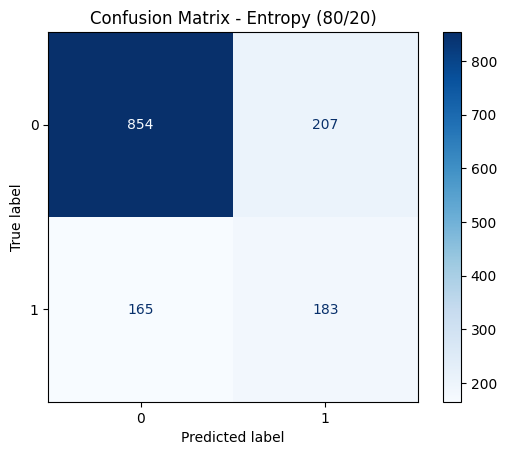

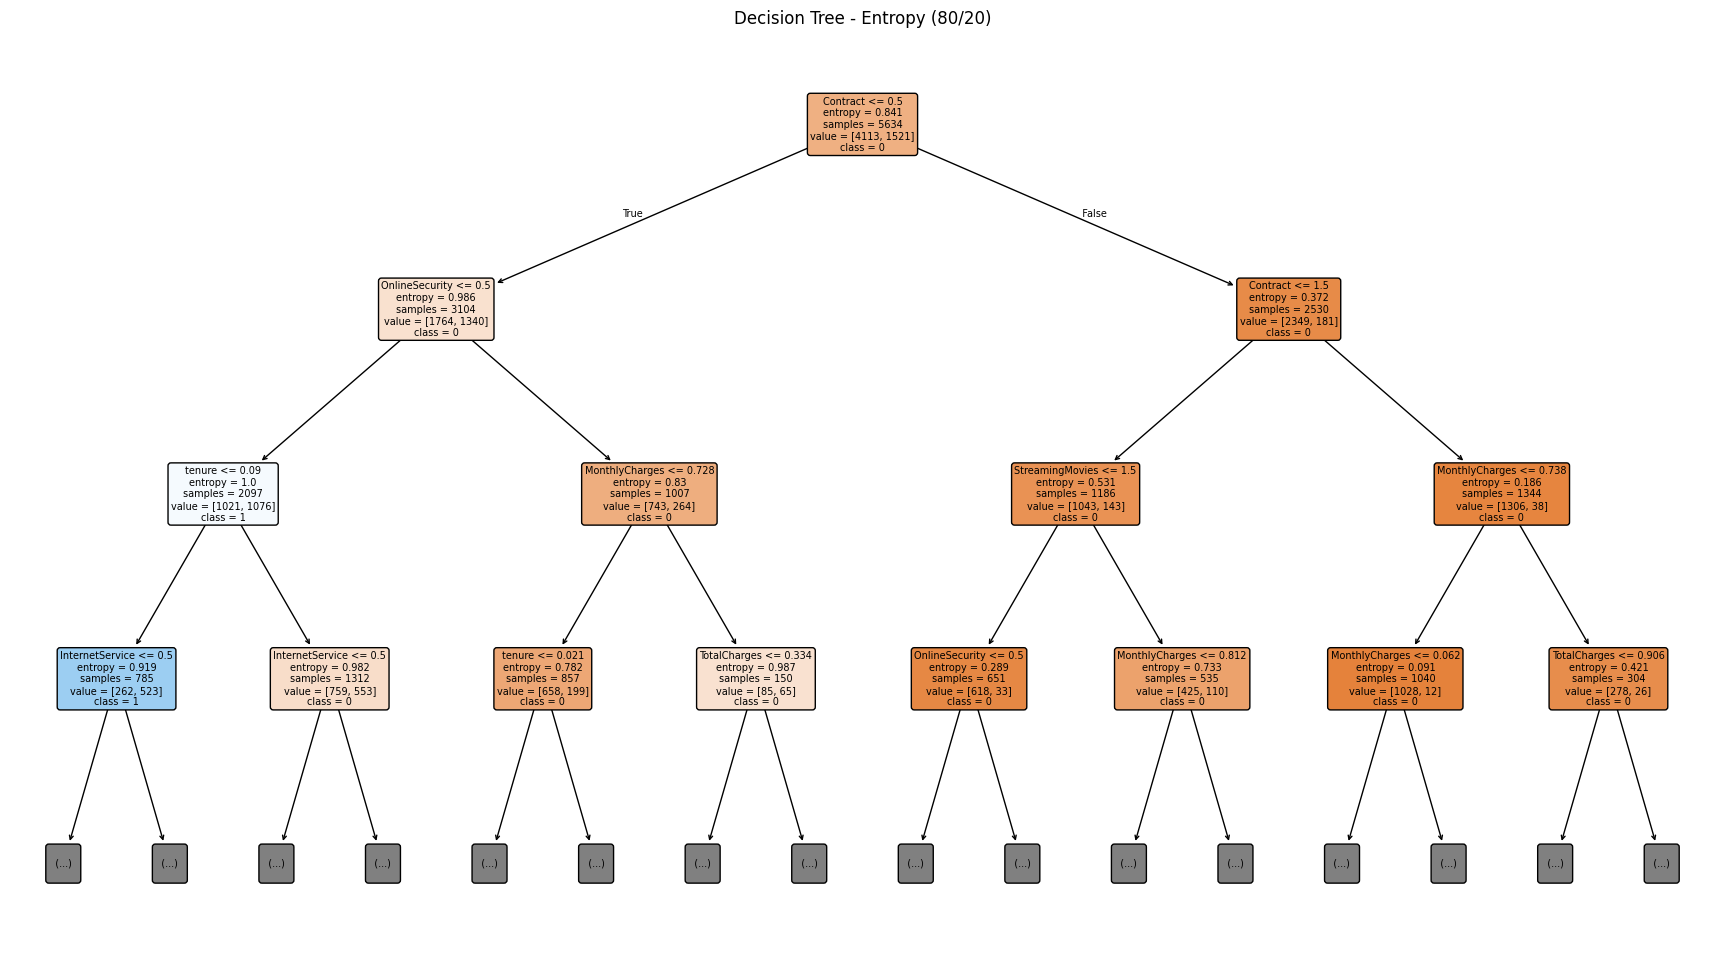

--- 70/30 (Entropy) ---
Accuracy: 0.7439659252247989
Confusion Matrix:
 [[1295  290]
 [ 251  277]]


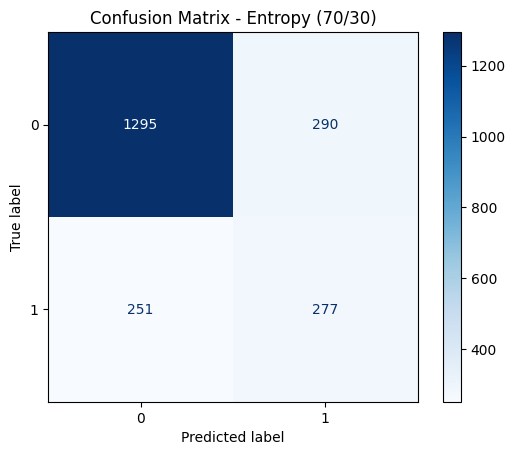

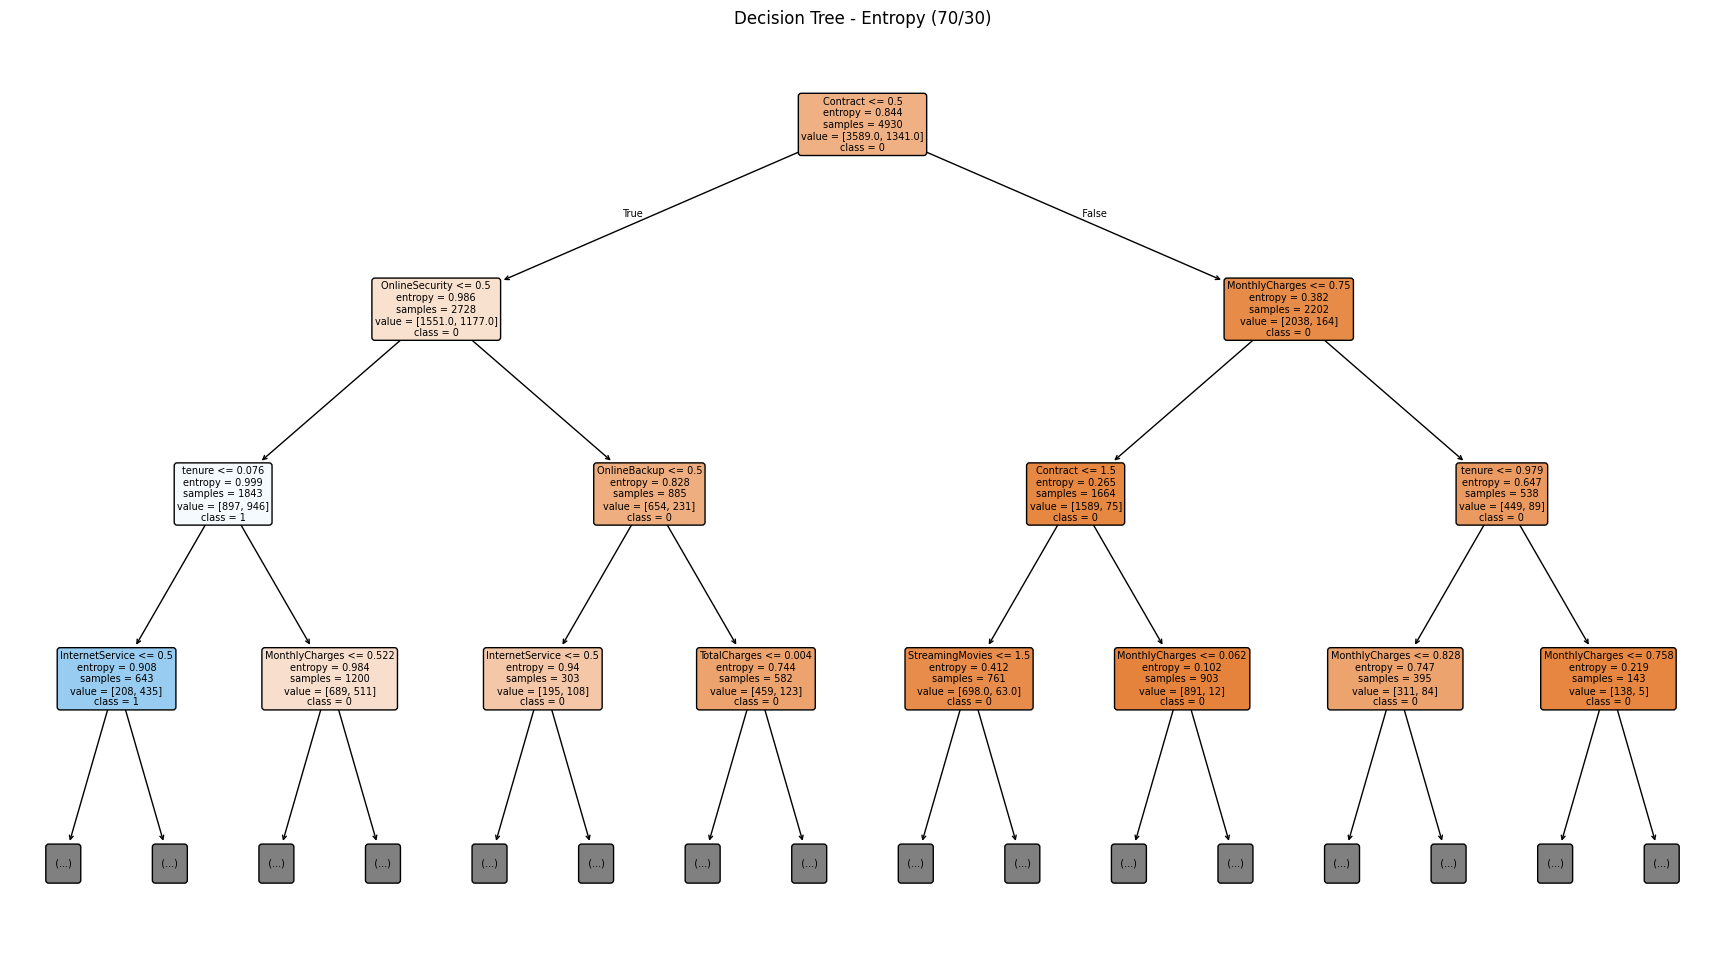

Split  Accuracy %  Depth
90/10       71.35     45
80/20       73.60     28
70/30       74.40     30


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

url = "https://raw.githubusercontent.com/LujainAldujain/Data_Mining_Project/refs/heads/main/Dataset/Preprocessed_dataset.csv"
df = pd.read_csv(url)

drop_cols = ['Churn', 'customerID']
X = df.drop(columns=[c for c in drop_cols if c in df.columns])
y = df['Churn']
cn = df['Churn'].unique().astype(str)
fn = X.columns.tolist()

splits = {"90/10": 0.1, "80/20": 0.2, "70/30": 0.3}
results = []

for name, ts in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=ts, random_state=1)

    clf = DecisionTreeClassifier(criterion="entropy", random_state=42)
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    acc = metrics.accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    print(f"--- {name} (Entropy) ---")
    print("Accuracy:", acc)
    print("Confusion Matrix:\n", cm)

    ConfusionMatrixDisplay(cm, display_labels=clf.classes_).plot(cmap="Blues")
    plt.title(f"Confusion Matrix - Entropy ({name})")
    plt.show()

    plt.figure(figsize=(22, 12))
    plot_tree(clf, feature_names=fn, class_names=[str(c) for c in clf.classes_],
              filled=True, rounded=True, fontsize=7, max_depth=3)
    plt.title(f"Decision Tree - Entropy ({name})")
    plt.show()

    results.append({"Split": name, "Accuracy %": round(acc * 100, 2), "Depth": clf.get_depth()})

print(pd.DataFrame(results).to_string(index=False))

### Entropy (Information Gain) Performance Summary Table

| Partition Size | Accuracy (Entropy) |
|---|---|
| **90% Training / 10% Testing** | 0.7134751773049646 |
| **80% Training / 20% Testing** | 0.7359829666430092 |
| **70% Training / 30% Testing** | 0.7439659252247989 |

#[7] Findings and Discussion

#[8] References